# 04 · Classification

Trains every classifier on every training set (real fold, class weights, baselines and LLMs),
evaluates on the real test fold, compares each method with **Real** and **ROS** using the paired
bootstrap, and saves everything under `artifacts/classification/<dataset>/`.

| Section | What it does | Saves |
|---|---|---|
| 1–2 | Setup and configuration | — |
| 3 | Data: cleaning, folds, protocol checks | — |
| 4 | Helpers: artifact loading/validation, training | — |
| 5 | Hyperparameter tuning (real fold only, reused if unchanged) | `tuning/best_params.json` |
| 6 | Classification | `results/fold_results.csv`, `results/predictions.csv`, `results/run_config.json` |
| 7 | Paired bootstrap vs Real and ROS | `results/paired_folds.csv`, `results/paired_summary.csv` |
| 8 | Aggregation across folds | `results/aggregated_results.csv` |
| 9 | EDA of the results | `results/figures/*.png` |

## 1. 📥 Setup

In [1]:
import hashlib
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src" / "tcibench" / "preparation" / "metadata.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the tcibench project.")

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from tcibench.classification import build_classifier, evaluate_classification, tune_classifier
from tcibench.classification.metrics import bootstrap_metric_differences
from tcibench.generation import check_artifact
from tcibench.preparation import Dataset, load_dataset, load_metadata
from tcibench.preparation.utils import dataframe_fingerprint
from tcibench.visualization import results_eda

## 2. ⚙️ Configuration

Paths

In [2]:
DATASET_ID = "sick"

RAW_PATHS = {
    "diabetes": PROJECT_ROOT / "data" / "raw" / "diabetes.csv",
    "sick": PROJECT_ROOT / "data" / "raw" / "sick.arff",
}

Models

In [3]:
CLASSIFIERS = ["logistic_regression", "random_forest", "xgboost", "tabpfn"]
BASELINE_METHODS = ["ros", "rus", "smotenc", "ctgan", "tvae", "ddpm"]
REFERENCES = ["real", "ros"] 
LLMS = {
    # "llm_glm_5_3": "z-ai_glm-5.3",
    "google_gemma-4-31b-it": "google_gemma-4-31b-it"
}

Protocol settings

In [4]:
# Protocol
SEED = 42
N_BOOTSTRAP = 2000              # paired comparisons: method - reference

METRICS = [
    "macro_f1", "auprc", "balanced_accuracy",
    "minority_precision", "minority_recall", "minority_f1",
]

# Set to True to ignore the saved hyperparameters and tune again.
RETUNE = False

In [5]:
GENERATION_ROOT = PROJECT_ROOT / "artifacts" / "generation" / DATASET_ID
OUTPUT_ROOT = PROJECT_ROOT / "artifacts" / "classification" / DATASET_ID
RESULTS_ROOT = OUTPUT_ROOT / "results"
FIGURES_ROOT = RESULTS_ROOT / "figures"
TUNING_PATH = OUTPUT_ROOT / "best_params.json"

for folder in (RESULTS_ROOT, FIGURES_ROOT, TUNING_PATH.parent):
    folder.mkdir(parents=True, exist_ok=True)

ARTIFACT_DIRS = {
    **{method: GENERATION_ROOT / "baselines" / method for method in BASELINE_METHODS},
    **{method: GENERATION_ROOT / "llms" / folder for method, folder in LLMS.items()},
}

METHODS = ["real", "class_weight", *ARTIFACT_DIRS]

## 3. 📂 Data

In [6]:
# Load dataset and metadata
metadata = load_metadata(DATASET_ID)

# Load raw dataset, clean it, and split into folds
raw = load_dataset(RAW_PATHS[DATASET_ID])
dataset = Dataset(raw, metadata)
cleaned, cleaning_report = dataset.preprocessing.clean(raw)
folds = dataset.preprocessing.split(cleaned)

TARGET = metadata.target_column
MINORITY_CLASS = cleaned[TARGET].value_counts().idxmin()
CATEGORICAL = [column for column in metadata.categorical_columns if column in cleaned.columns]

# Without categorical features, SMOTE-NC is SMOTE and its files are saved under baselines/smote/.
if not CATEGORICAL:
    ARTIFACT_DIRS = {
        ("smote" if method == "smotenc" else method): (
            folder.with_name("smote") if method == "smotenc" else folder
        )
        for method, folder in ARTIFACT_DIRS.items()
    }
    METHODS = ["real", "class_weight", *ARTIFACT_DIRS]

# Models need numeric classes (XGBoost). Only the arrays given to the models are encoded; data and CSVs keep the original labels.
target_encoder = LabelEncoder().fit(cleaned[TARGET])
MINORITY_CODE = int(target_encoder.transform([MINORITY_CLASS])[0])

In [7]:
fold_rows = []

for fold_id, (train, test, _) in enumerate(folds):
    counts = train[TARGET].value_counts()
    minority, majority = counts.idxmin(), counts.idxmax()

    fold_rows.append({
        "fold": fold_id,
        "train_rows": len(train),
        "test_rows": len(test),
        "train_minority": int(counts[minority]),
        "train_majority": int(counts[majority]),
        "imbalance_ratio": round(counts[majority] / counts[minority], 2),
        "records_to_generate": int(counts[majority] - counts[minority]),
        "test_minority": int((test[TARGET] == minority).sum()),
    })

fold_summary = pd.DataFrame(fold_rows).set_index("fold")
display(fold_summary)

print(f"{metadata.display_name} | target: {TARGET} | minority class: {MINORITY_CLASS!r} "
      f"(encoded as {MINORITY_CODE})")

display(pd.Series(cleaning_report, name="cleaning").to_frame())

,train_rows,test_rows,train_minority,train_majority,imbalance_ratio,records_to_generate,test_minority
fold,,,,,,,
0,2113,529,169,1944,11.50,1775,43
1,2113,529,169,1944,11.50,1775,43
2,2114,528,170,1944,11.44,1774,42
3,2114,528,170,1944,11.44,1774,42
4,2114,528,170,1944,11.44,1774,42


Thyroid Sick | target: Class | minority class: 'sick' (encoded as 1)


,cleaning
original_rows,3772
cleaned_rows,2642
dropped_columns,[TBG]
all_missing_columns,[TBG]
missing_values_before_cleaning,6064
missing_values_by_column_before_cleaning,"{'age': 1, 'sex': 150, 'TSH': 369, 'T3': 769, ..."
removed_missing_rows,1129
removed_duplicate_rows,1
numeric_decimals,4
target_counts_before_cleaning,"{'negative': 3541, 'sick': 231}"


## 4. 🧰 Helpers

In [8]:
def file_sha256(path):
    """Hash of an artifact file, so results can be traced back to the exact CSV."""
    return hashlib.sha256(Path(path).read_bytes()).hexdigest() if path else None

def load_artifact(method, fold_id, train):
    """Read one generated artifact and validate it against the training fold."""

    path = ARTIFACT_DIRS[method] / f"fold_{fold_id}.csv"

    # Categorical columns and the target keep the dtype of the training fold.
    dtypes = {column: train[column].dtype for column in [*CATEGORICAL, TARGET]}
    artifact = pd.read_csv(path, dtype=dtypes)

    if set(artifact.columns) == set(train.columns):
        artifact = artifact[train.columns]

    counts = train[TARGET].value_counts()
    minority, majority = counts.idxmin(), counts.idxmax()

    if method == "rus":   # majority rows kept, as many as the minority rows
        expected_rows, expected_label = counts[minority], majority
    else:                 # new minority rows up to 1:1
        expected_rows, expected_label = counts[majority] - counts[minority], minority

    check_artifact(
        artifact,
        train,
        target_column=TARGET,
        expected_rows=int(expected_rows),
        expected_label=expected_label,
    )

    return artifact, path

def training_set(method, fold_id, train):
    """Training data for one method: the real fold, or the fold combined with its artifact."""

    if method in ("real", "class_weight"):
        return train, None

    artifact, path = load_artifact(method, fold_id, train)

    if method == "rus":
        minority_rows = train[train[TARGET] == MINORITY_CLASS]
        return pd.concat([artifact, minority_rows], ignore_index=True), path

    return pd.concat([train, artifact], ignore_index=True), path

def fit_and_predict(classifier_name, method, params, train_set, test):
    """Train one classifier and predict the test fold."""

    X_train = train_set.drop(columns=[TARGET])
    y_train = target_encoder.transform(train_set[TARGET])
    X_test = test.drop(columns=[TARGET])

    model_params = dict(params)
    fit_kwargs = {}

    if method == "class_weight" and classifier_name != "tabpfn":
        if classifier_name == "xgboost":
            # XGBoost has no class_weight: balanced weights per sample instead.
            fit_kwargs["classifier__sample_weight"] = compute_sample_weight("balanced", y_train)
        else:
            model_params["class_weight"] = "balanced"

    model = build_classifier(classifier_name, X_train, seed=SEED, model_params=model_params)
    model.fit(X_train, y_train, **fit_kwargs)

    positive_column = list(model.classes_).index(MINORITY_CODE)

    return (
        model.predict(X_test),
        model.predict_proba(X_test)[:, positive_column],
        model_params,
    )

def to_json(value):
    """JSON encoder for numpy values in parameters and reports."""
    return value.item() if hasattr(value, "item") else str(value)

## 5. 🎛️ Hyperparameter tuning

Tuned with inner cross-validation on the **real training fold only**, then reused by every method
of that fold, so differences between methods come from the training data and not from tuning.
TabPFN uses its defaults. Saved parameters are reused while the folds are unchanged
(set `RETUNE = True` to force a new search).

In [9]:
fold_fingerprints = {
    str(fold_id): dataframe_fingerprint(train) for fold_id, (train, _, _) in enumerate(folds)
}

In [10]:
fold_fingerprints = { str(fold_id): dataframe_fingerprint(train) for fold_id, (train, _, _) in enumerate(folds)}

# Load previously tuned parameters if available and valid, otherwise tune classifiers for each fold.
saved = json.loads(TUNING_PATH.read_text(encoding="utf-8")) if TUNING_PATH.is_file() else None

can_reuse = (
    saved is not None
    and not RETUNE
    and saved.get("train_fingerprints") == fold_fingerprints
    and all(set(CLASSIFIERS) <= set(fold) for fold in saved["best_params"].values())
)

if can_reuse:
    best_params = saved["best_params"]
    print(f"Reusing tuned parameters: {TUNING_PATH.relative_to(PROJECT_ROOT)}")

else:
    best_params = {}

    for fold_id, (train, _, _) in enumerate(folds):
        X_train = train.drop(columns=[TARGET])
        y_train = target_encoder.transform(train[TARGET])
        best_params[str(fold_id)] = {}

        for classifier_name in CLASSIFIERS:
            if classifier_name == "tabpfn":
                best_params[str(fold_id)][classifier_name] = {"params": {}, "score": None}
                continue

            estimator = build_classifier(classifier_name, X_train, seed=SEED)
            params, score = tune_classifier(classifier_name, estimator, X_train, y_train, seed=SEED)

            best_params[str(fold_id)][classifier_name] = {"params": params, "score": score}
            print(f"Fold {fold_id} | {classifier_name:20s} | inner-CV Macro-F1: {score:.4f}")

    TUNING_PATH.write_text(
        json.dumps({"train_fingerprints": fold_fingerprints, "best_params": best_params}, indent=2, default=to_json), encoding="utf-8",
    )
    
    best_params = json.loads(TUNING_PATH.read_text(encoding="utf-8"))["best_params"]
    print(f"Saved: {TUNING_PATH.relative_to(PROJECT_ROOT)}")

display(pd.DataFrame([
    {"fold": int(fold), "classifier": name, "inner_cv_macro_f1": entry["score"],
     "params": entry["params"] or "default"}
    for fold, classifiers in best_params.items()
    for name, entry in classifiers.items()
]).set_index(["fold", "classifier"]))

Fold 0 | logistic_regression  | inner-CV Macro-F1: 0.8325
Fold 0 | random_forest        | inner-CV Macro-F1: 0.9325
Fold 0 | xgboost              | inner-CV Macro-F1: 0.9414
Fold 1 | logistic_regression  | inner-CV Macro-F1: 0.8409
Fold 1 | random_forest        | inner-CV Macro-F1: 0.9173
Fold 1 | xgboost              | inner-CV Macro-F1: 0.9504
Fold 2 | logistic_regression  | inner-CV Macro-F1: 0.8280
Fold 2 | random_forest        | inner-CV Macro-F1: 0.9169
Fold 2 | xgboost              | inner-CV Macro-F1: 0.9424
Fold 3 | logistic_regression  | inner-CV Macro-F1: 0.8427
Fold 3 | random_forest        | inner-CV Macro-F1: 0.9196
Fold 3 | xgboost              | inner-CV Macro-F1: 0.9514
Fold 4 | logistic_regression  | inner-CV Macro-F1: 0.8426
Fold 4 | random_forest        | inner-CV Macro-F1: 0.9238
Fold 4 | xgboost              | inner-CV Macro-F1: 0.9434
Saved: artifacts/classification/sick/best_params.json


inner_cv_macro_f1  \
fold classifier                               
0    logistic_regression           0.832498   
     random_forest                 0.932467   
     xgboost                       0.941387   
     tabpfn                             NaN   
1    logistic_regression           0.840857   
     random_forest                 0.917301   
     xgboost                       0.950435   
     tabpfn                             NaN   
2    logistic_regression           0.828042   
     random_forest                 0.916938   
     xgboost                       0.942399   
     tabpfn                             NaN   
3    logistic_regression           0.842699   
     random_forest                 0.919638   
     xgboost                       0.951434   
     tabpfn                             NaN   
4    logistic_regression           0.842585   
     random_forest                 0.923811   
     xgboost                       0.943350   
     tabpfn                             NaN   

                                                                     params  
fold classifier                                                              
0    logistic_regression                                           {'C': 5}  
     random_forest                 {'max_depth': None, 'n_estimators': 500}  
     xgboost              {'learning_rate': 0.05, 'max_depth': 6, 'n_est...  
     tabpfn                                                         default  
1    logistic_regression                                           {'C': 5}  
     random_forest                 {'max_depth': None, 'n_estimators': 300}  
     xgboost              {'learning_rate': 0.1, 'max_depth': 6, 'n_esti...  
     tabpfn                                                         default  
2    logistic_regression                                           {'C': 5}  
     random_forest                   {'max_depth': 20, 'n_estimators': 300}  
     xgboost              {'learning_rate': 0.05, 'max_depth': 4, 'n_est...  
     tabpfn                                                         default  
3    logistic_regression                                          {'C': 50}  
     random_forest                 {'max_depth': None, 'n_estimators': 300}  
     xgboost              {'learning_rate': 0.05, 'max_depth': 8, 'n_est...  
     tabpfn                                                         default  
4    logistic_regression                                           {'C': 5}  
     random_forest                 {'max_depth': None, 'n_estimators': 300}  
     xgboost              {'learning_rate': 0.1, 'max_depth': 6, 'n_esti...  
     tabpfn                                                         default

## 6. 🤖 Classification

One model per fold × method × classifier, always evaluated on the untouched real test fold.
Methods with a missing artifact in any fold are skipped as a whole, because the paired comparisons
need all five folds.

In [11]:
missing = {
    method: [fold for fold in range(len(folds)) if not (folder / f"fold_{fold}.csv").is_file()]
    for method, folder in ARTIFACT_DIRS.items()
}

missing = {method: fold_ids for method, fold_ids in missing.items() if fold_ids}

RUN_METHODS = [method for method in METHODS if method not in missing]

for method, fold_ids in missing.items():
    print(f"Skipping {method}: missing artifacts for folds {fold_ids}")
    
print(f"Methods: {RUN_METHODS}")

Methods: ['real', 'class_weight', 'ros', 'rus', 'smotenc', 'ctgan', 'tvae', 'ddpm', 'google_gemma-4-31b-it']


In [12]:
results = []
predictions = []

for fold_id, (train, test, _) in enumerate(folds):
    y_test = target_encoder.transform(test[TARGET])
    test_fingerprint = dataframe_fingerprint(test)

    for method in RUN_METHODS:
        train_set, artifact_path = training_set(method, fold_id, train)
        scores = []

        for classifier_name in CLASSIFIERS:
            if method == "class_weight" and classifier_name in ["tabpfn"]:
                continue

            # Load best params
            params = best_params[str(fold_id)][classifier_name]["params"]
            # Fit and predict 
            y_pred, positive_proba, model_params = fit_and_predict(classifier_name, method, params, train_set, test)
            # Calculate metrics
            metrics = evaluate_classification(y_test, y_pred, positive_proba, minority_class=MINORITY_CODE)

            results.append({
                "fold": fold_id,
                "classifier": classifier_name,
                "method": method,
                "train_rows": len(train_set),
                "parameters": json.dumps(model_params, sort_keys=True, default=to_json),
                "train_fingerprint": dataframe_fingerprint(train_set),
                "test_fingerprint": test_fingerprint,
                "artifact_path": str(artifact_path.relative_to(PROJECT_ROOT)) if artifact_path else None,
                "artifact_sha256": file_sha256(artifact_path),
                **metrics,
            })

            predictions.append(pd.DataFrame({
                "fold": fold_id,
                "classifier": classifier_name,
                "method": method,
                "test_row": np.arange(len(test)),
                "y_true": y_test,
                "y_pred": y_pred,
                "positive_proba": positive_proba,
            }))
            
            scores.append(f"{classifier_name}={metrics['macro_f1']:.3f}")

        print(f"Fold {fold_id} | {method:14s} | Macro-F1: " + "  ".join(scores))

fold_results = pd.DataFrame(results)
predictions_df = pd.concat(predictions, ignore_index=True)

/home/labian-3/Documentos/Fernanda/tcibench/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fold 0 | real           | Macro-F1: logistic_regression=0.851  random_forest=0.875  xgboost=0.923  tabpfn=0.922
Fold 0 | class_weight   | Macro-F1: logistic_regression=0.766  random_forest=0.894  xgboost=0.935
Fold 0 | ros            | Macro-F1: logistic_regression=0.757  random_forest=0.878  xgboost=0.947  tabpfn=0.783
Fold 0 | rus            | Macro-F1: logistic_regression=0.760  random_forest=0.904  xgboost=0.883  tabpfn=0.857
Fold 0 | smotenc        | Macro-F1: logistic_regression=0.768  random_forest=0.900  xgboost=0.930  tabpfn=0.872
Fold 0 | ctgan          | Macro-F1: logistic_regression=0.821  random_forest=0.881  xgboost=0.903  tabpfn=0.928
Fold 0 | tvae           | Macro-F1: logistic_regression=0.811  random_forest=0.903  xgboost=0.935  tabpfn=0.926
Fold 0 | ddpm           | Macro-F1: logistic_regression=0.759  random_forest=0.881  xgboost=0.911  tabpfn=0.919
Fold 0 | google_gemma-4-31b-it | Macro-F1: logistic_regression=0.760  random_forest=0.894  xgboost=0.890  tabpfn=0.905

In [13]:
fold_results.to_csv(RESULTS_ROOT / "fold_results.csv", index=False)
predictions_df.to_csv(RESULTS_ROOT / "predictions.csv", index=False)

run_config = {
    "dataset": DATASET_ID,
    "MINORITY_CLASS": MINORITY_CLASS,
    "MINORITY_CODE": MINORITY_CODE,
    "seed": SEED,
    "n_folds": len(folds),
    "classifiers": CLASSIFIERS,
    "methods": RUN_METHODS,
    "skipped_methods": missing,
    "llm_runs": LLMS,
    "class_weight_not_applicable": sorted(["tabpfn"]),
    "n_bootstrap": N_BOOTSTRAP,
    "references": REFERENCES,
    "train_fingerprints": fold_fingerprints,
    "tuning_file": str(TUNING_PATH.relative_to(PROJECT_ROOT)),
}

(RESULTS_ROOT / "run_config.json").write_text(
    json.dumps(run_config, indent=2, default=to_json), encoding="utf-8"
)

print(f"Saved fold_results.csv ({len(fold_results)} rows), predictions.csv "
      f"({len(predictions_df)} rows) and run_config.json in {RESULTS_ROOT.relative_to(PROJECT_ROOT)}")

Saved fold_results.csv (175 rows), predictions.csv (92470 rows) and run_config.json in artifacts/classification/sick/results


## 7. ⚖️ Paired comparisons (bootstrap)

For each fold, classifier and method, a **paired, class-stratified bootstrap** of
`method − reference` on the same test fold (B = 2000, 95% percentile CI), against Real and ROS.

- `paired_folds.csv`: one CI per fold (what the bootstrap actually estimates).
- `paired_summary.csv`: mean ± sd of Δ across the 5 folds, and in how many folds the CI is entirely
  above / below zero.

The per-fold CI bounds are **not** averaged into a single CI: an average of intervals is not an
interval for the average.

In [14]:
groups = {
    key: group.sort_values("test_row")
    for key, group in predictions_df.groupby(["fold", "classifier", "method"], sort=False)
}

paired_rows = []

for (fold_id, classifier_name, method), current in groups.items():
    for reference in REFERENCES:
        base = groups.get((fold_id, classifier_name, reference))
        # Real vs ROS would only repeat ROS vs Real with the sign flipped.
        if base is None or method == reference or (method == "real" and reference != "real"):
            continue

        differences = bootstrap_metric_differences(
            current["y_true"].to_numpy(),
            current["y_pred"].to_numpy(),
            current["positive_proba"].to_numpy(),
            base["y_pred"].to_numpy(),
            base["positive_proba"].to_numpy(),
            minority_class=MINORITY_CODE,
            n_bootstrap=N_BOOTSTRAP,
            random_seed=SEED,
        )

        for metric, values in differences.items():
            paired_rows.append({
                "fold": fold_id, "classifier": classifier_name, "method": method,
                "reference": reference, "metric": metric, **values,
            })

paired_folds = pd.DataFrame(paired_rows)

paired_summary = (
    paired_folds
    .assign(
        ci_above_zero=lambda frame: frame["ci_lower"] > 0,
        ci_below_zero=lambda frame: frame["ci_upper"] < 0,
    )
    .groupby(["classifier", "method", "reference", "metric"], sort=False)
    .agg(
        delta_mean=("difference", "mean"),
        delta_std=("difference", "std"),
        folds=("difference", "size"),
        folds_ci_above_zero=("ci_above_zero", "sum"),
        folds_ci_below_zero=("ci_below_zero", "sum"),
    )
    .reset_index()
)

paired_folds.to_csv(RESULTS_ROOT / "paired_folds.csv", index=False)
paired_summary.to_csv(RESULTS_ROOT / "paired_summary.csv", index=False)
print(f"Saved paired_folds.csv ({len(paired_folds)} rows) and paired_summary.csv")

Saved paired_folds.csv (1740 rows) and paired_summary.csv


## 8. 📊 Aggregated results

Mean and standard deviation of each metric across the 5 folds. The sd is the variability of each
method between folds, not the uncertainty of a difference between methods (that is section 7).

In [15]:
aggregated_results = (
    fold_results
    .groupby(["classifier", "method"], sort=False)[METRICS]
    .agg(["mean", "std"])
)

aggregated_results.columns = [f"{metric}_{stat}" for metric, stat in aggregated_results.columns]
aggregated_results = aggregated_results.reset_index()

aggregated_results.to_csv(RESULTS_ROOT / "aggregated_results.csv", index=False, float_format="%.4f")
print(f"Saved aggregated_results.csv ({len(aggregated_results)} rows)")

display(
    aggregated_results
    .pivot(index="method", columns="classifier", values="macro_f1_mean")
    .reindex(index=RUN_METHODS, columns=CLASSIFIERS)
    .round(3)
    .rename_axis("Macro-F1 (mean of 5 folds)")
)

Saved aggregated_results.csv (35 rows)


classifier,logistic_regression,random_forest,xgboost,tabpfn
Macro-F1 (mean of 5 folds),,,,
real,0.841,0.926,0.951,0.944
class_weight,0.752,0.941,0.946,NaN
ros,0.751,0.936,0.955,0.723
rus,0.742,0.882,0.897,0.890
smotenc,0.751,0.938,0.952,0.924
ctgan,0.766,0.900,0.915,0.919
tvae,0.762,0.908,0.927,0.942
ddpm,0.729,0.928,0.942,0.938
google_gemma-4-31b-it,0.743,0.889,0.904,0.908


## 9. 🔎 EDA of the results

Reading notes:
- Δ in the figures is in **percentage points** (+1.5 = +0.015).
- Blue = LLM methods; Real in black; everything else in gray.
- Macro-F1 up with AUPRC flat is *compatible* with a threshold shift, not evidence of a better
  ranking of the positive class.
- AUPRC is not comparable across datasets: its chance level is the positive-class prevalence.

In [16]:
# Load saved results (to look at them without retraining)
aggregated_results = pd.read_csv(RESULTS_ROOT / "aggregated_results.csv")
paired_summary = pd.read_csv(RESULTS_ROOT / "paired_summary.csv")

### 9.1 Checks

In [17]:
for message in results_eda.checks(aggregated_results):
    print(message)

n/a: Pesos por classe em TabPFN (não se aplica)


### 9.2 Figures

01_delta_vs_real.png


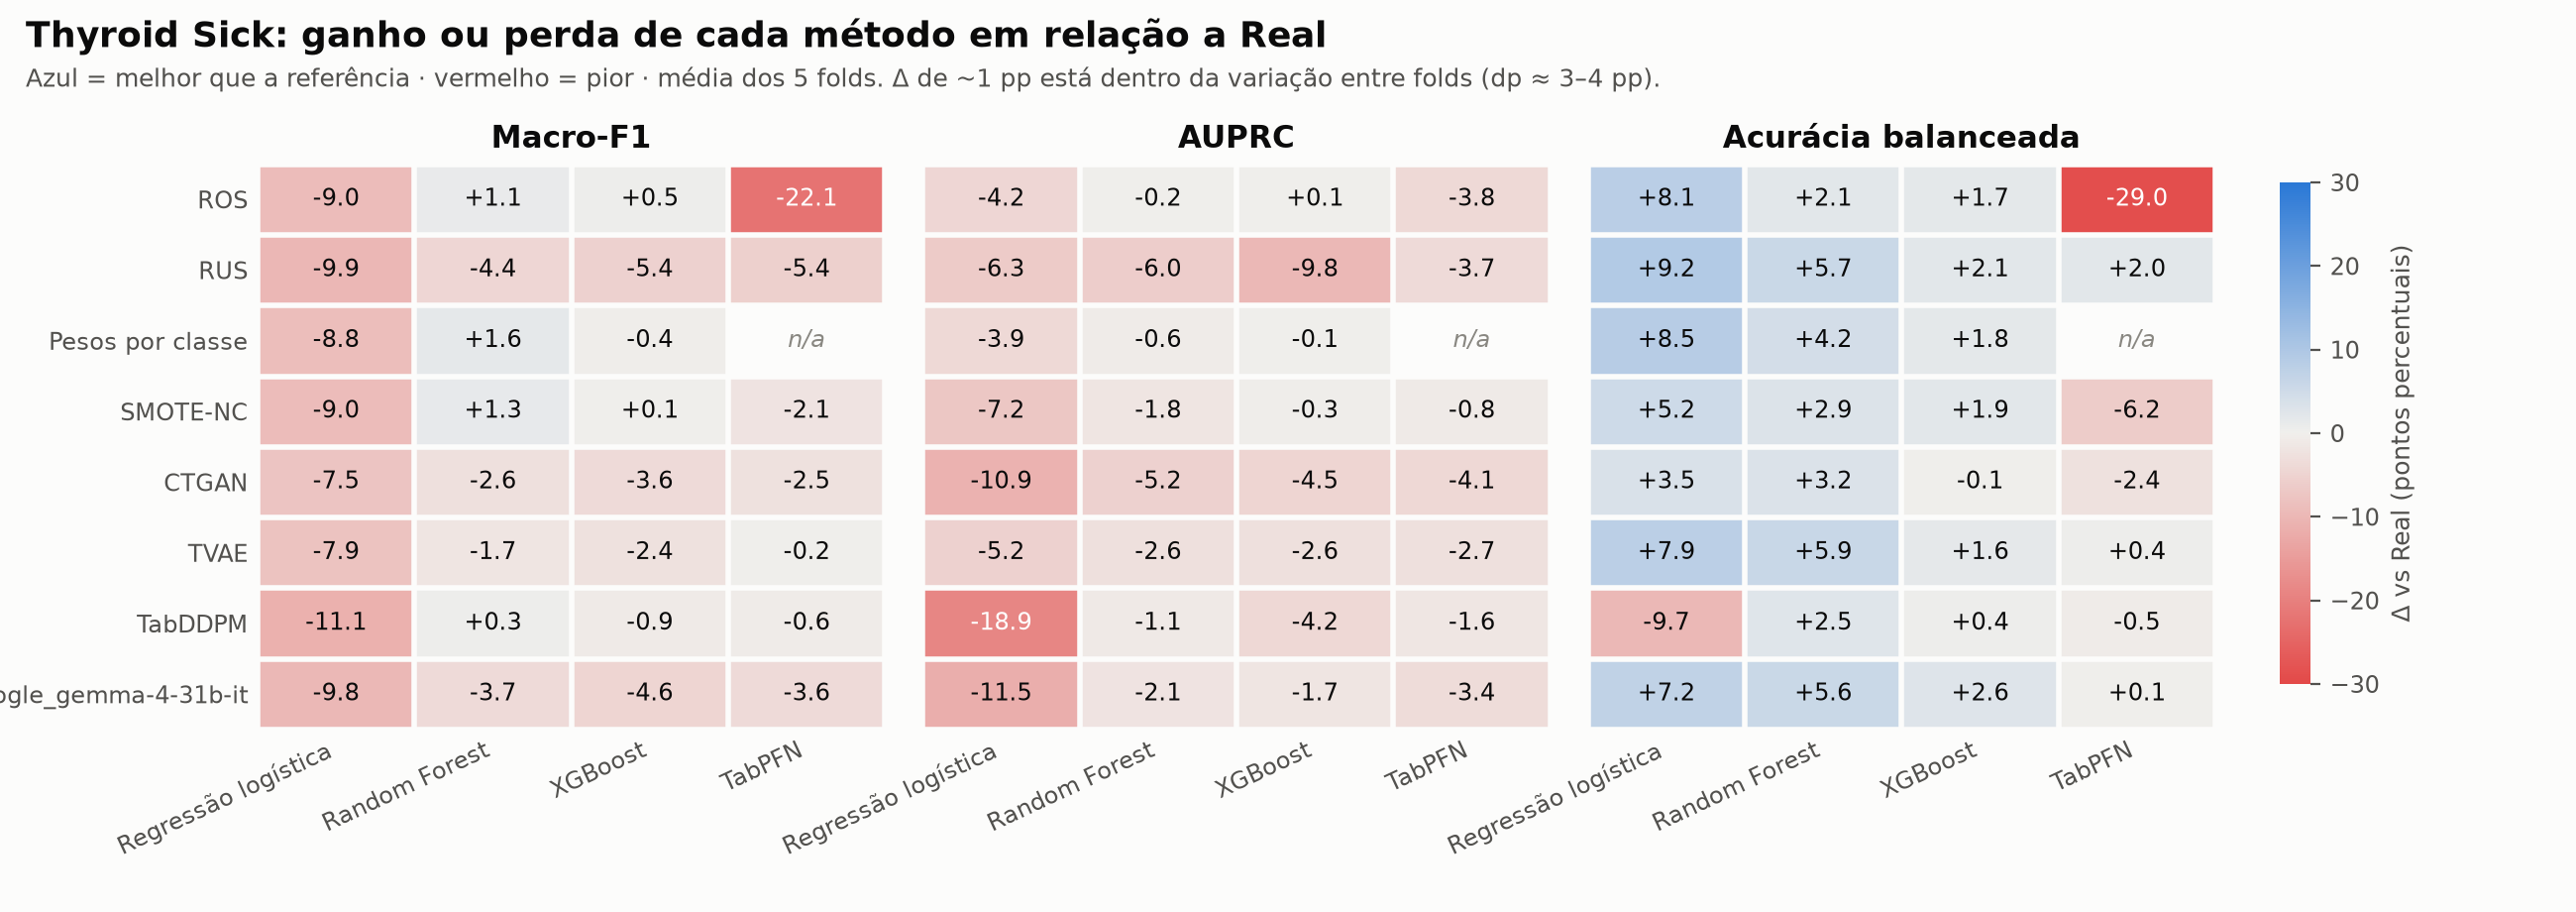

02_delta_vs_ros.png


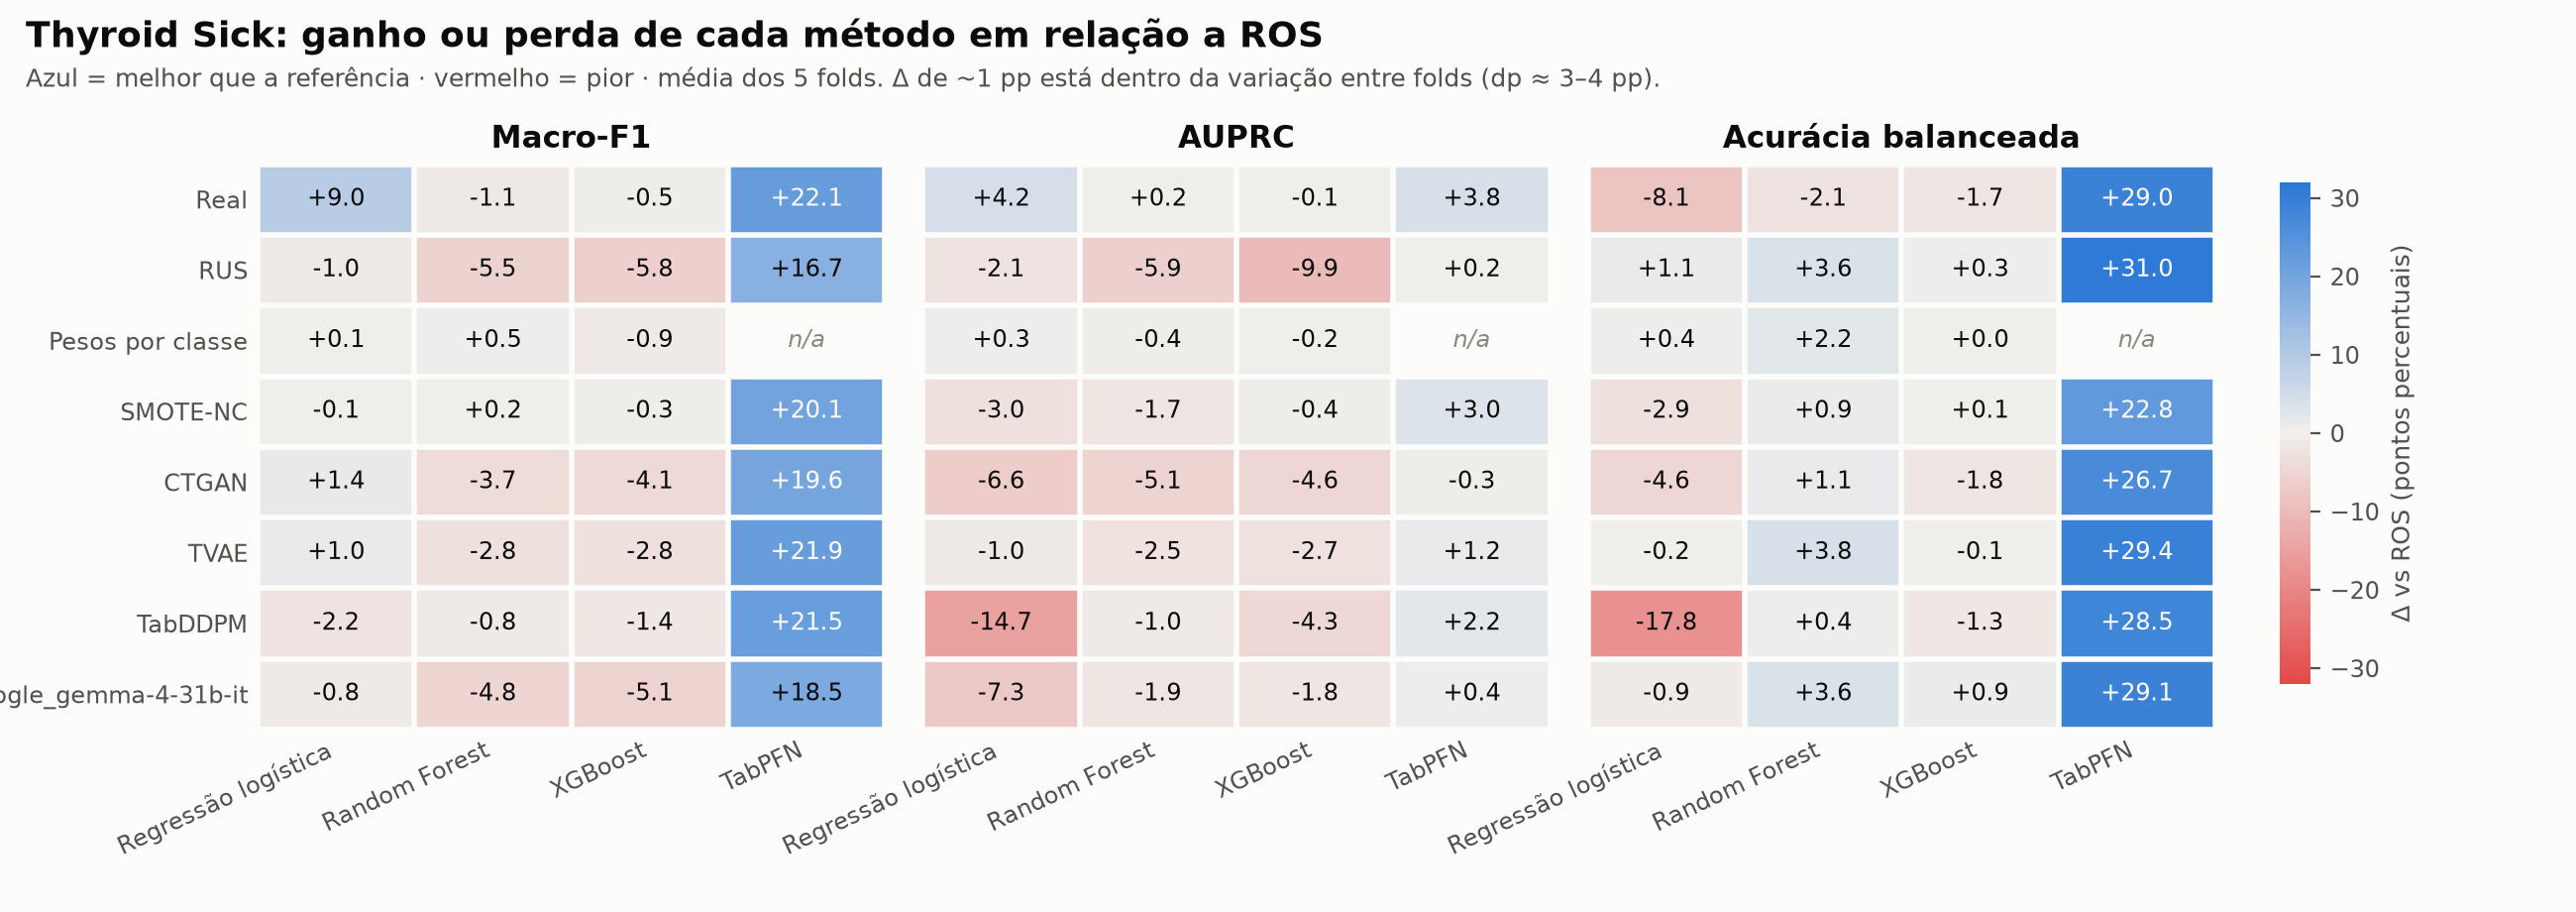

03_macro_f1_dots.png


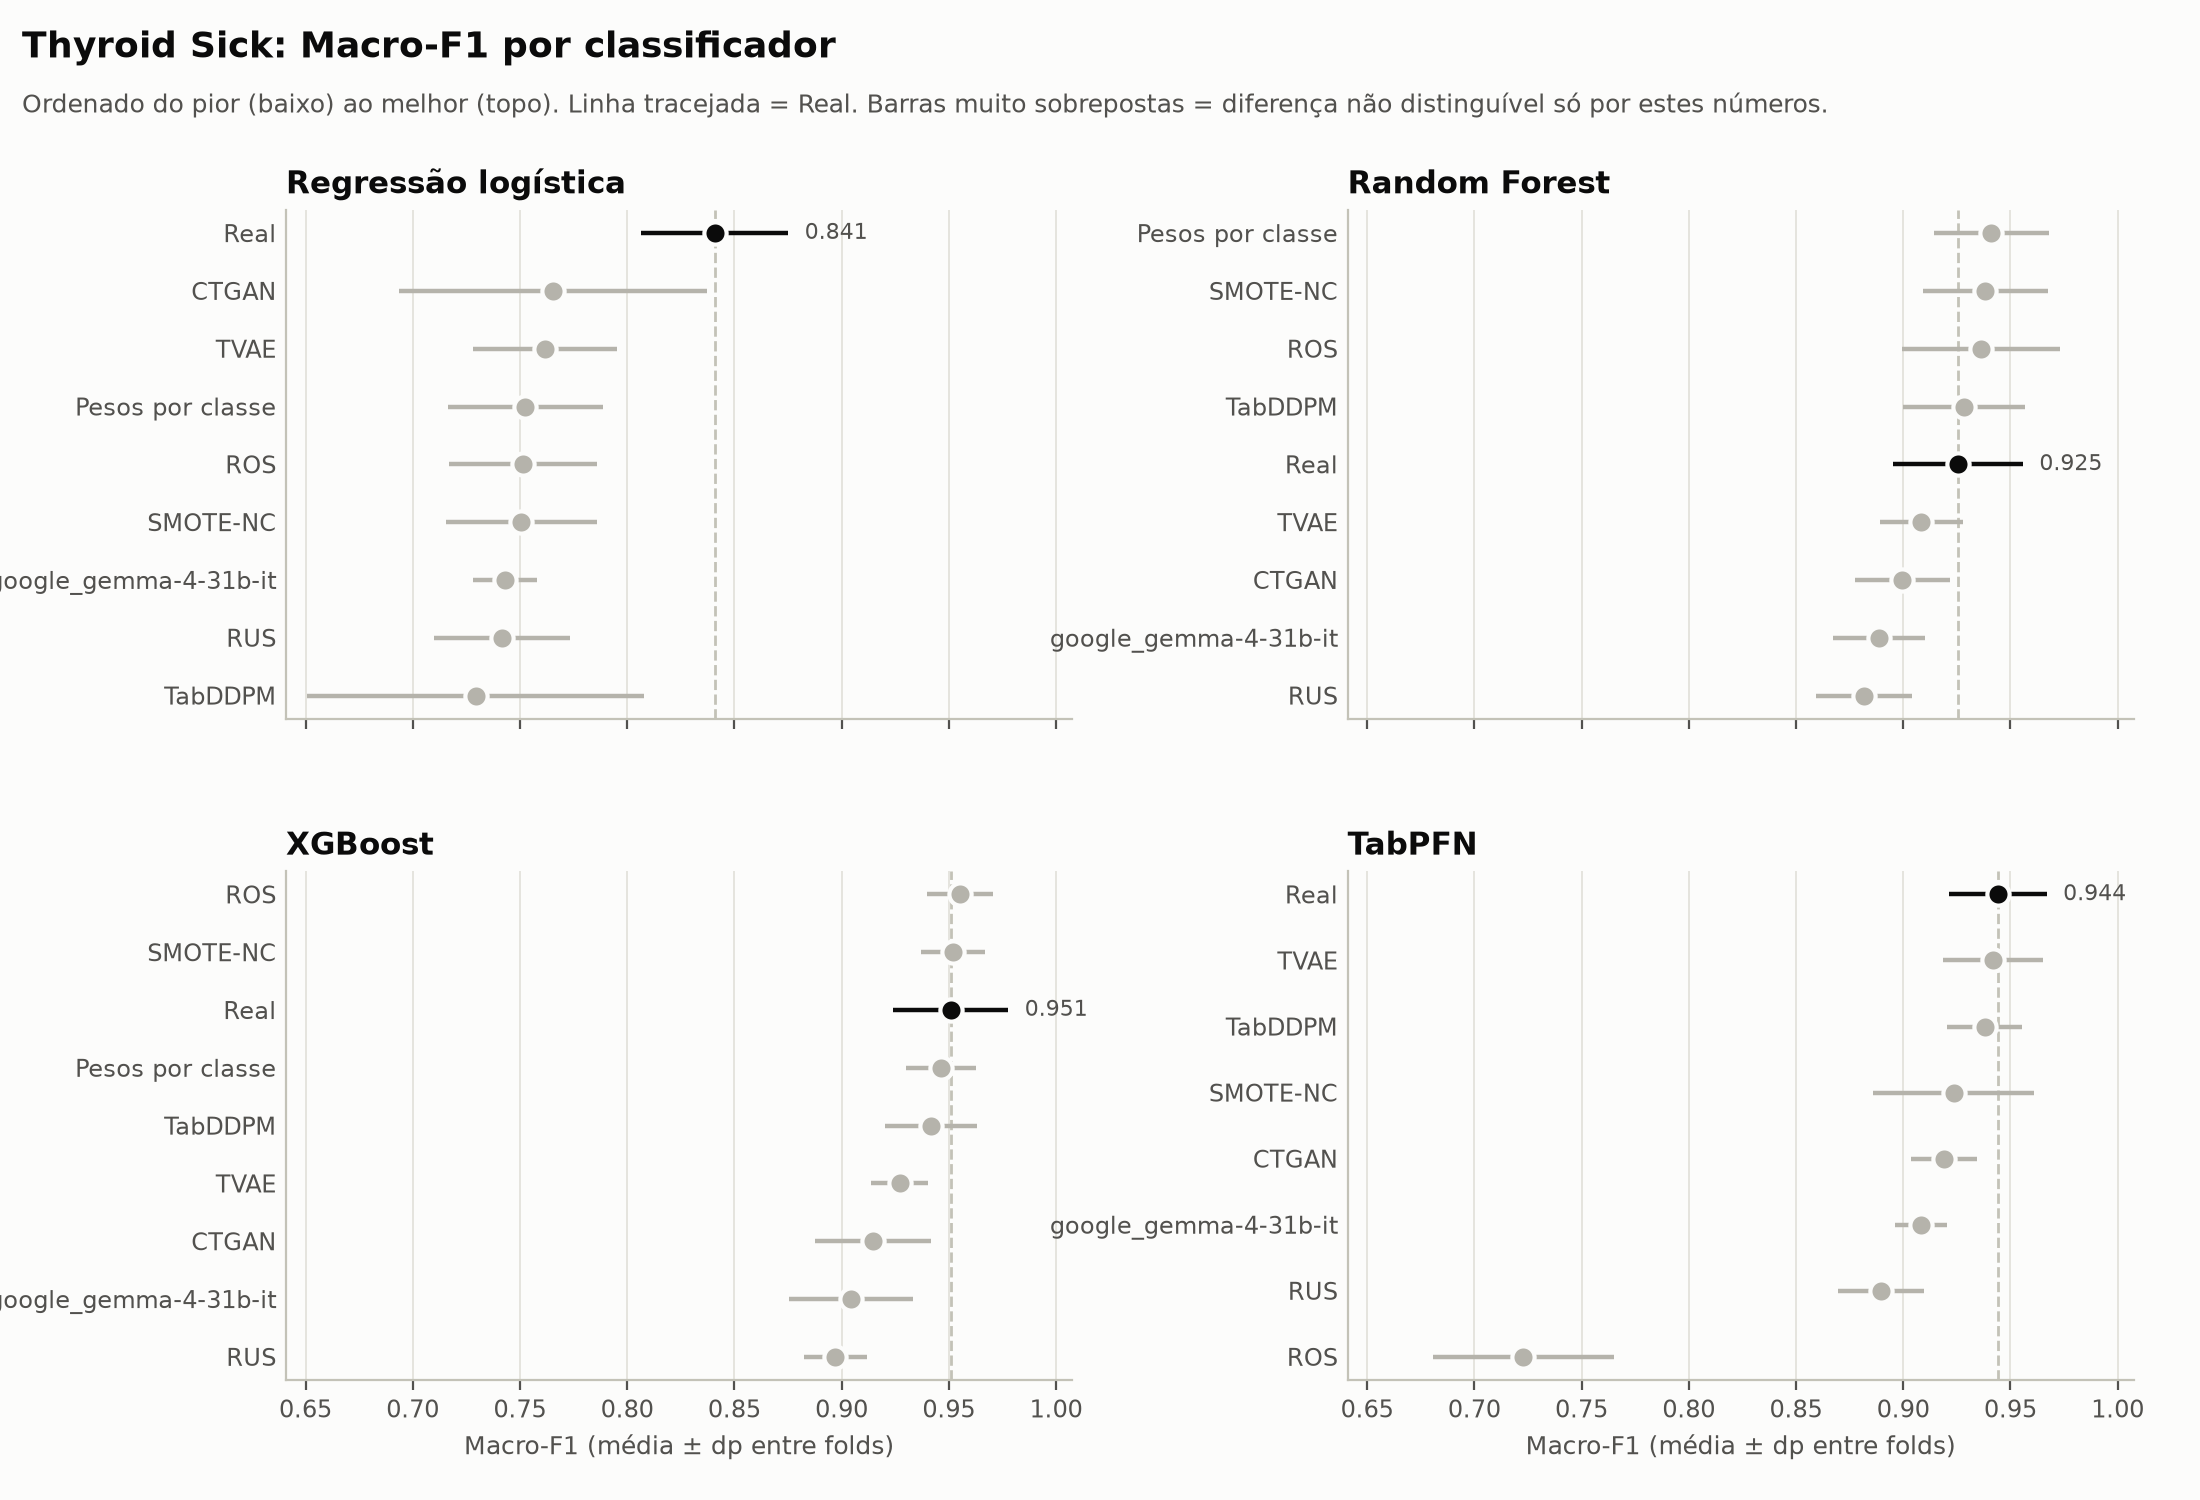

04_precision_recall.png


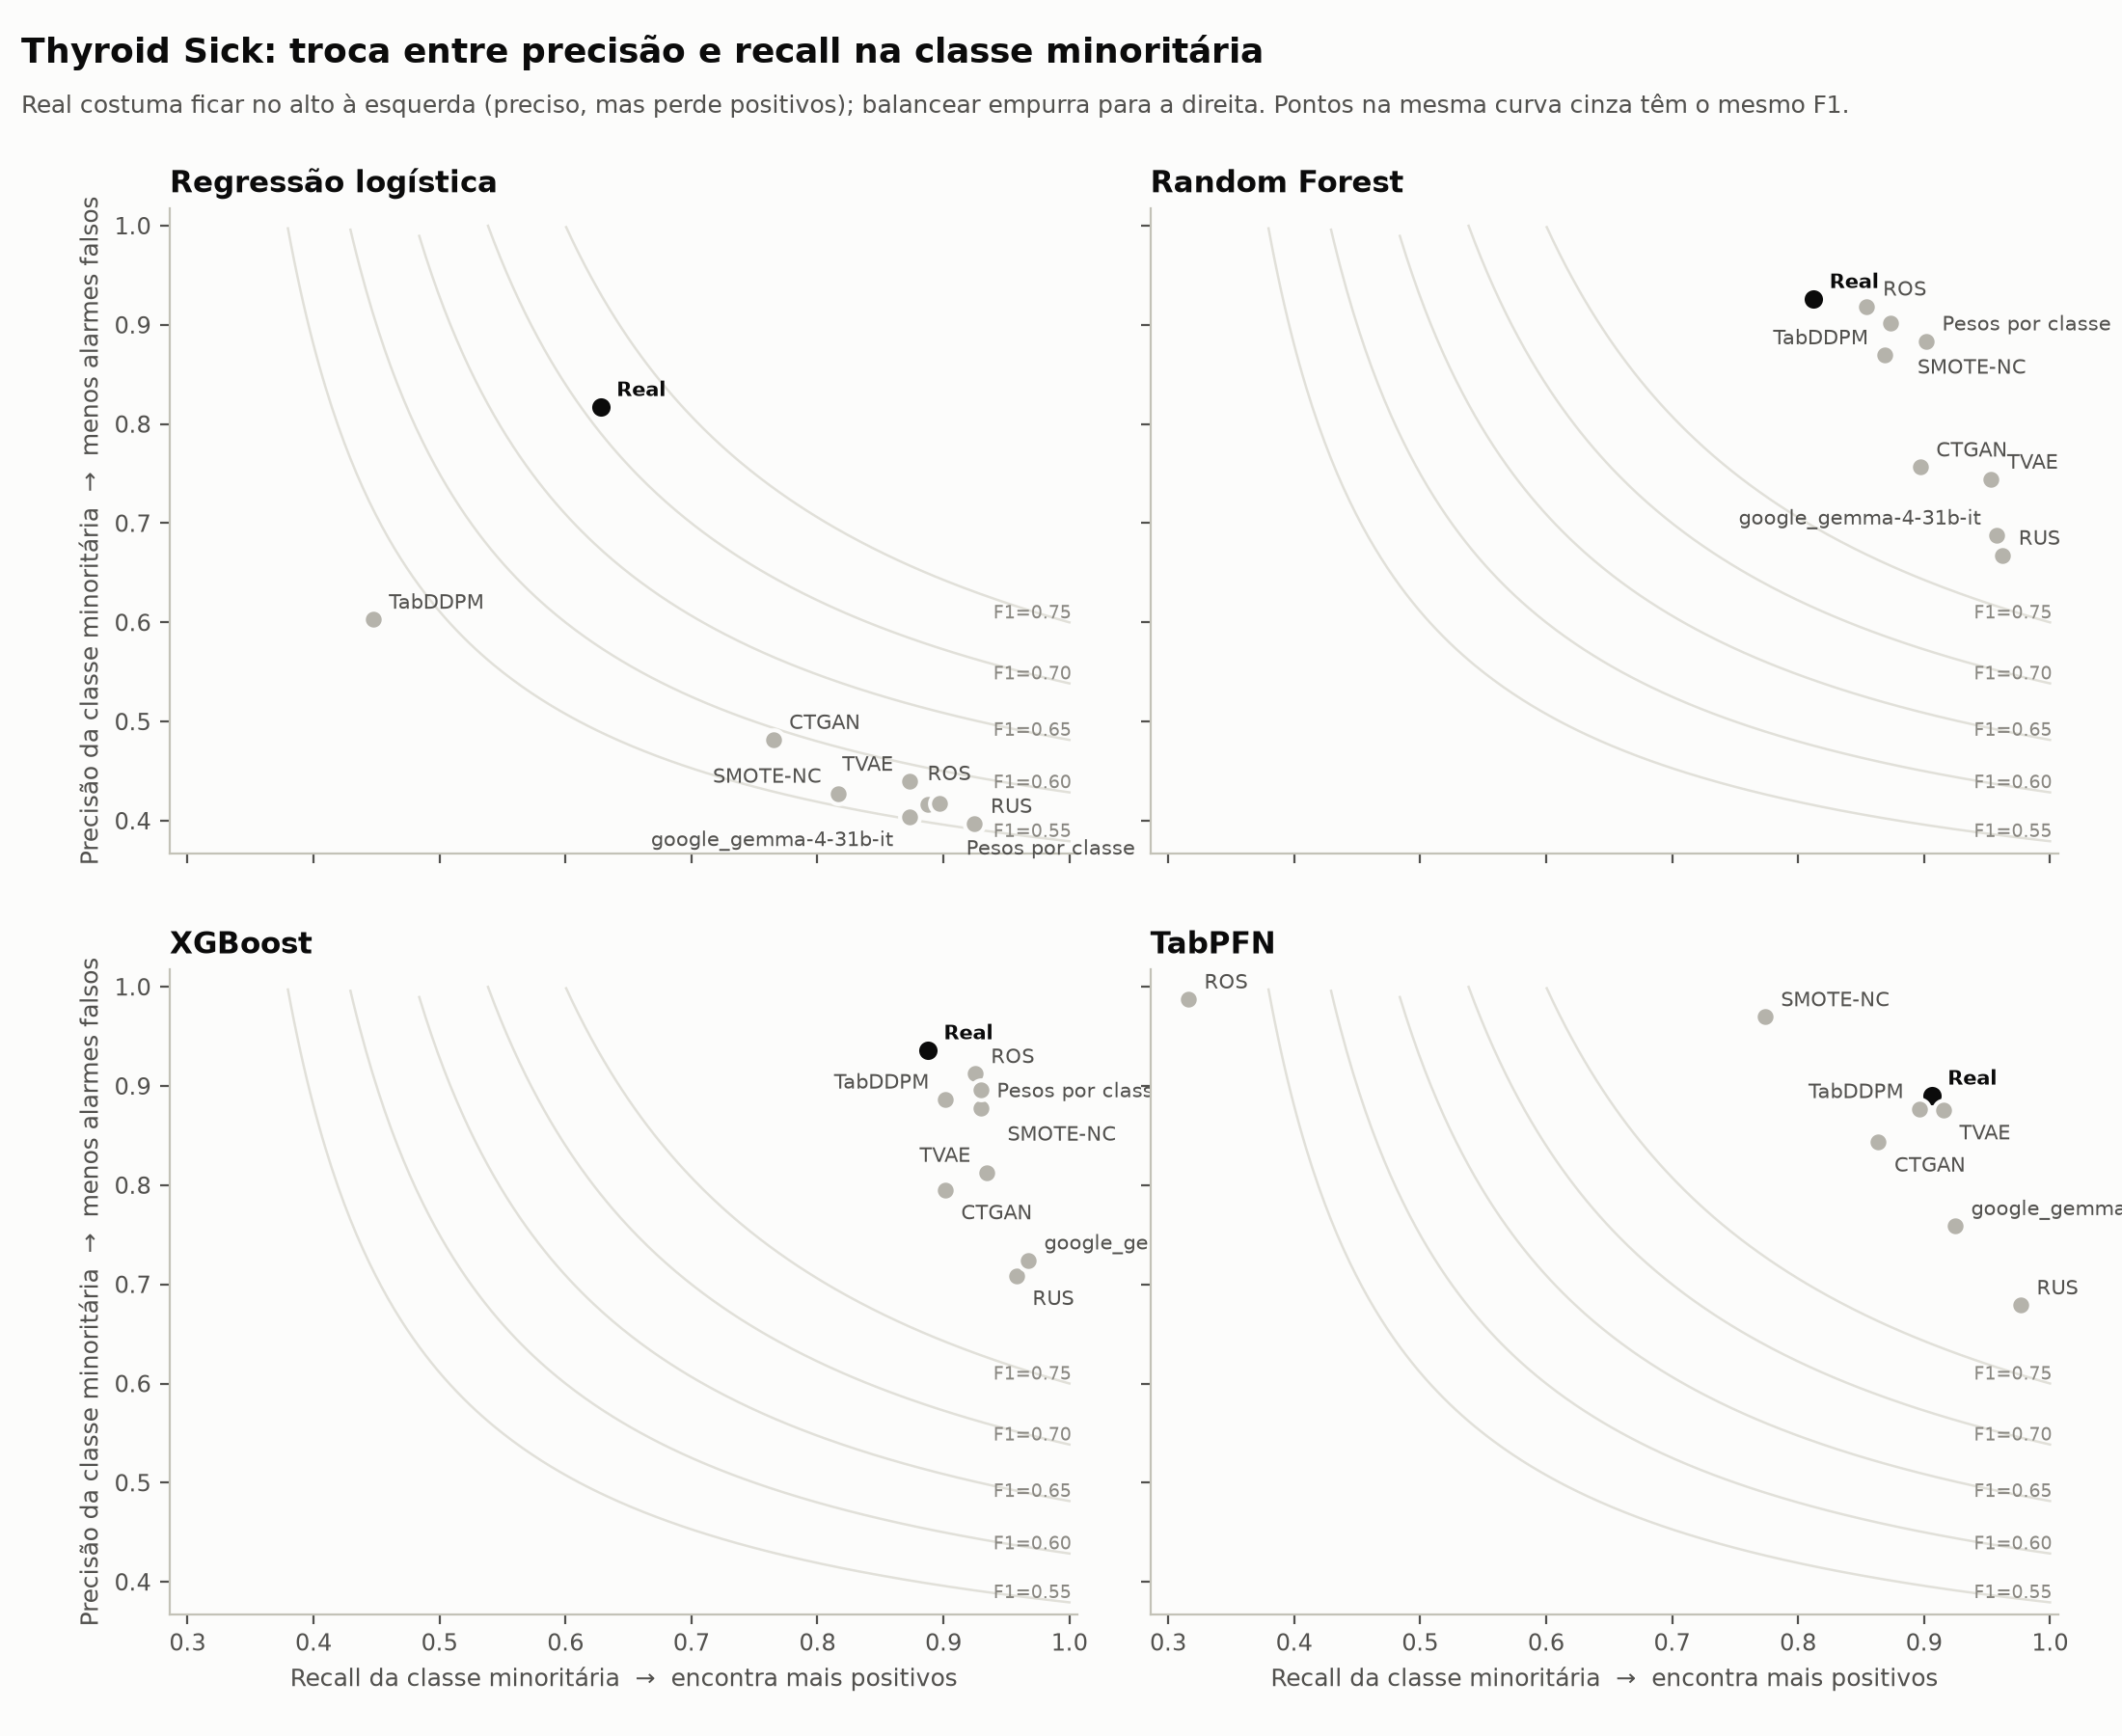

05_f1_vs_auprc.png


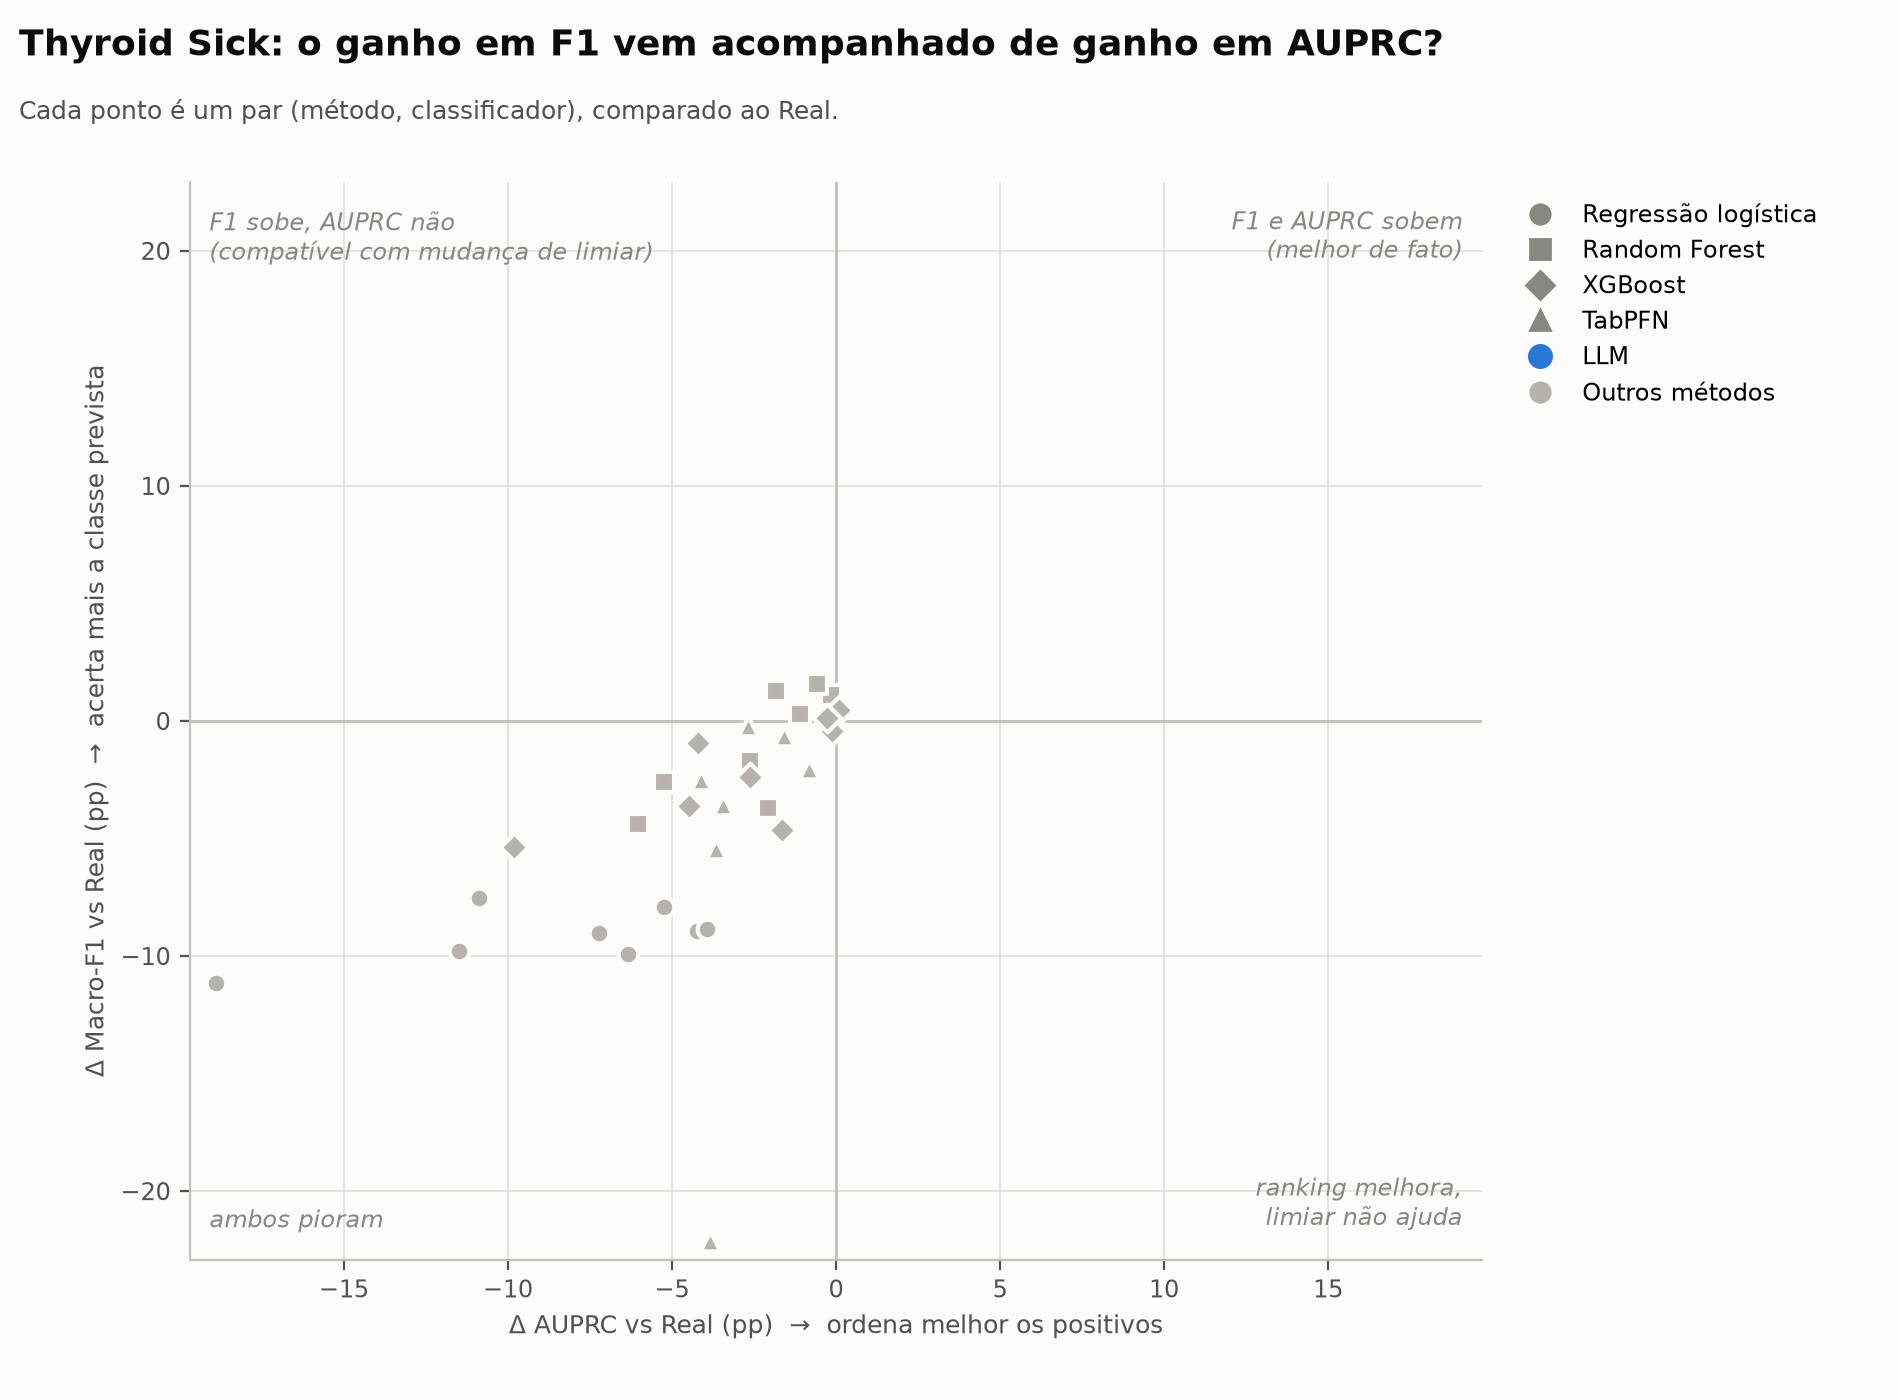

06_mean_rank.png


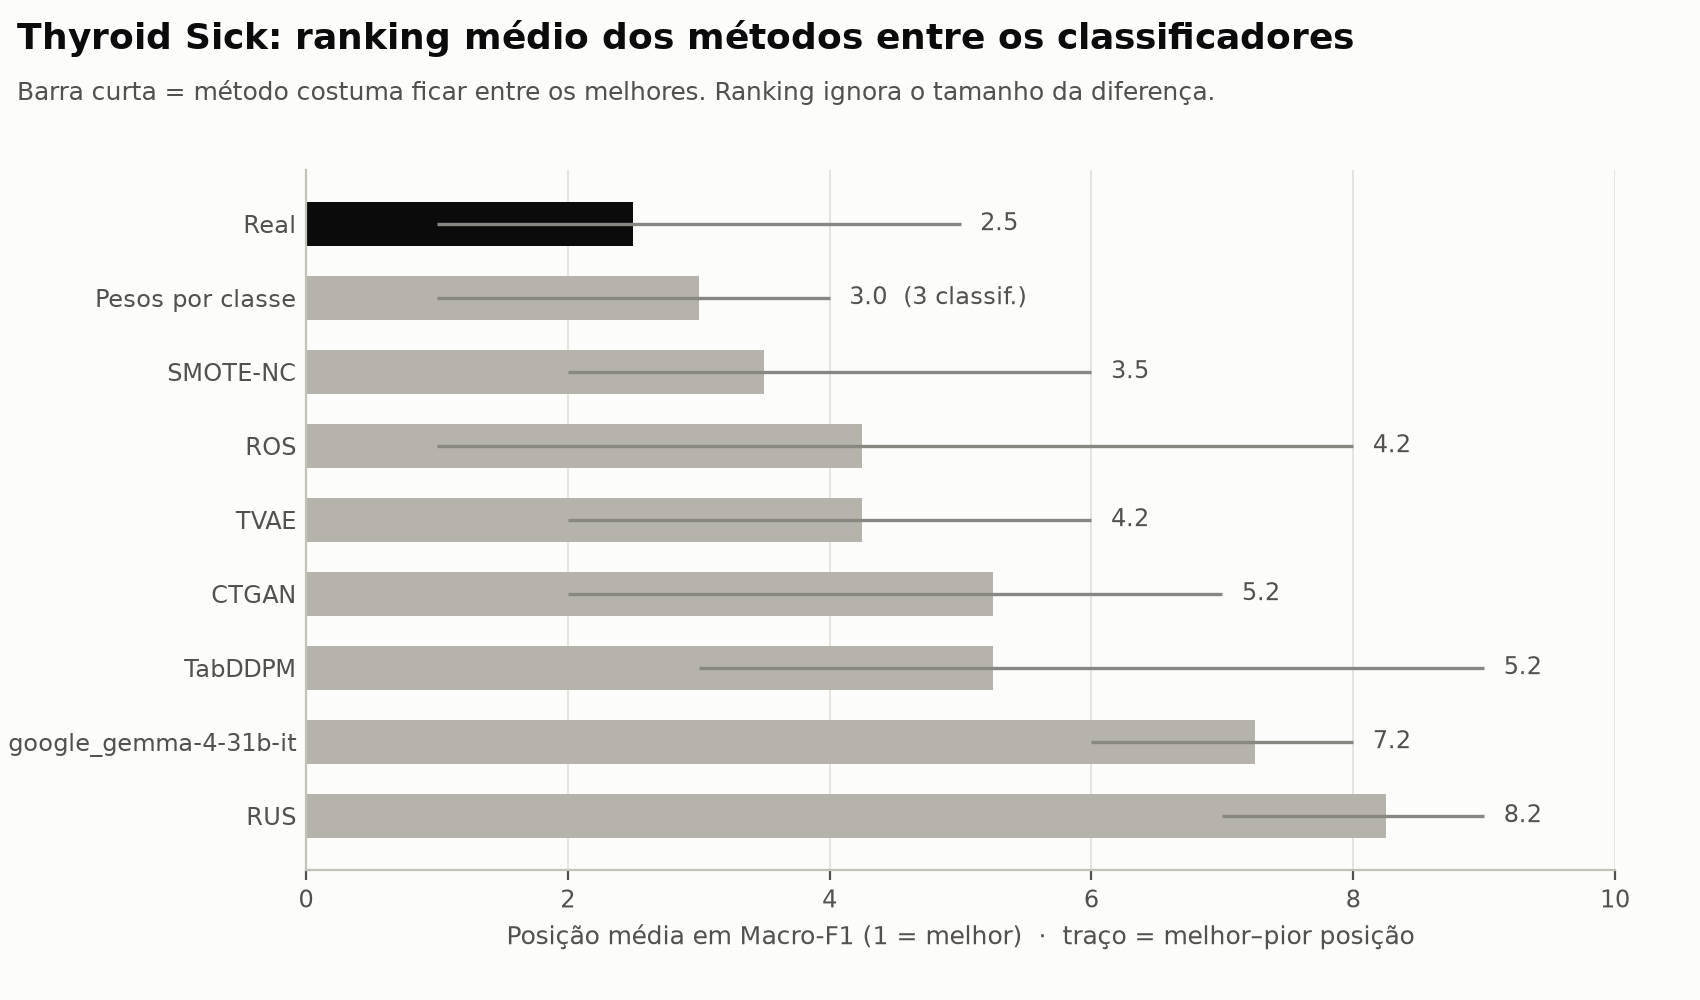

In [18]:
figure_paths = results_eda.make_figures(
    aggregated_results, FIGURES_ROOT, dataset=metadata.display_name
)

for name, path in figure_paths.items():
    print(name)
    display(Image(filename=str(path)))

### 9.3 Paired differences vs Real

Δ mean ± sd across folds, and `↑k / ↓k`: in how many of the 5 folds the bootstrap CI was entirely
above / below zero.

In [19]:
def paired_table(reference, metrics=("macro_f1", "auprc", "balanced_accuracy")):
    rows = paired_summary[
        (paired_summary["reference"] == reference) & paired_summary["metric"].isin(metrics)
    ].copy()
    rows["cell"] = rows.apply(
        lambda row: (
            f"{row.delta_mean:+.3f} ± {row.delta_std:.3f} "
            f"(↑{row.folds_ci_above_zero} / ↓{row.folds_ci_below_zero})"
        ),
        axis=1,
    )
    order = pd.MultiIndex.from_product(
        [list(metrics), [m for m in RUN_METHODS if m in set(rows["method"])]],
        names=["metric", "method"],
    )
    return (
        rows.pivot(index=["metric", "method"], columns="classifier", values="cell")
        .reindex(index=order, columns=CLASSIFIERS)
        .fillna("n/a")
    )


display(paired_table("real"))

classifier                                    logistic_regression  \
metric            method                                            
macro_f1          class_weight           -0.088 ± 0.058 (↑0 / ↓4)   
                  ros                    -0.089 ± 0.055 (↑0 / ↓4)   
                  rus                    -0.099 ± 0.047 (↑0 / ↓4)   
                  smotenc                -0.090 ± 0.057 (↑0 / ↓4)   
                  ctgan                  -0.075 ± 0.060 (↑0 / ↓2)   
                  tvae                   -0.079 ± 0.049 (↑0 / ↓3)   
                  ddpm                   -0.111 ± 0.097 (↑0 / ↓4)   
                  google_gemma-4-31b-it  -0.098 ± 0.038 (↑0 / ↓4)   
auprc             class_weight           -0.039 ± 0.034 (↑0 / ↓2)   
                  ros                    -0.042 ± 0.043 (↑0 / ↓2)   
                  rus                    -0.063 ± 0.040 (↑0 / ↓3)   
                  smotenc                -0.072 ± 0.047 (↑0 / ↓3)   
                  ctgan                  -0.109 ± 0.099 (↑0 / ↓3)   
                  tvae                   -0.052 ± 0.028 (↑0 / ↓2)   
                  ddpm                   -0.189 ± 0.078 (↑0 / ↓4)   
                  google_gemma-4-31b-it  -0.115 ± 0.037 (↑0 / ↓4)   
balanced_accuracy class_weight           +0.085 ± 0.061 (↑2 / ↓0)   
                  ros                    +0.081 ± 0.051 (↑3 / ↓0)   
                  rus                    +0.092 ± 0.043 (↑4 / ↓0)   
                  smotenc                +0.052 ± 0.077 (↑2 / ↓1)   
                  ctgan                  +0.035 ± 0.032 (↑2 / ↓0)   
                  tvae                   +0.079 ± 0.055 (↑3 / ↓0)   
                  ddpm                   -0.097 ± 0.123 (↑0 / ↓2)   
                  google_gemma-4-31b-it  +0.072 ± 0.047 (↑3 / ↓0)   

classifier                                          random_forest  \
metric            method                                            
macro_f1          class_weight           +0.016 ± 0.007 (↑0 / ↓0)   
                  ros                    +0.011 ± 0.012 (↑0 / ↓0)   
                  rus                    -0.044 ± 0.041 (↑0 / ↓4)   
                  smotenc                +0.013 ± 0.012 (↑0 / ↓0)   
                  ctgan                  -0.026 ± 0.028 (↑0 / ↓2)   
                  tvae                   -0.017 ± 0.036 (↑0 / ↓1)   
                  ddpm                   +0.003 ± 0.002 (↑0 / ↓0)   
                  google_gemma-4-31b-it  -0.037 ± 0.039 (↑0 / ↓1)   
auprc             class_weight           -0.006 ± 0.009 (↑0 / ↓0)   
                  ros                    -0.001 ± 0.009 (↑0 / ↓0)   
                  rus                    -0.060 ± 0.059 (↑0 / ↓4)   
                  smotenc                -0.018 ± 0.013 (↑0 / ↓0)   
                  ctgan                  -0.052 ± 0.027 (↑0 / ↓3)   
                  tvae                   -0.026 ± 0.018 (↑0 / ↓2)   
                  ddpm                   -0.011 ± 0.013 (↑0 / ↓2)   
                  google_gemma-4-31b-it  -0.021 ± 0.013 (↑0 / ↓1)   
balanced_accuracy class_weight           +0.042 ± 0.014 (↑3 / ↓0)   
                  ros                    +0.021 ± 0.016 (↑0 / ↓0)   
                  rus                    +0.057 ± 0.043 (↑2 / ↓0)   
                  smotenc                +0.029 ± 0.024 (↑2 / ↓0)   
                  ctgan                  +0.032 ± 0.013 (↑1 / ↓0)   
                  tvae                   +0.059 ± 0.031 (↑3 / ↓0)   
                  ddpm                   +0.025 ± 0.024 (↑1 / ↓0)   
                  google_gemma-4-31b-it  +0.056 ± 0.045 (↑3 / ↓0)   

classifier                                                xgboost  \
metric            method                                            
macro_f1          class_weight           -0.004 ± 0.021 (↑0 / ↓1)   
                  ros                    +0.004 ± 0.015 (↑0 / ↓0)   
                  rus                    -0.054 ± 0.030 (↑0 / ↓2)   
                  smotenc                +0.001 ± 0.027 (↑0 / ↓1)

In [20]:
if "ros" in RUN_METHODS:
    display(paired_table("ros"))

classifier                                    logistic_regression  \
metric            method                                            
macro_f1          class_weight           +0.001 ± 0.007 (↑0 / ↓0)   
                  rus                    -0.010 ± 0.013 (↑0 / ↓0)   
                  smotenc                -0.001 ± 0.011 (↑0 / ↓0)   
                  ctgan                  +0.014 ± 0.060 (↑2 / ↓1)   
                  tvae                   +0.010 ± 0.029 (↑1 / ↓0)   
                  ddpm                   -0.022 ± 0.081 (↑0 / ↓1)   
                  google_gemma-4-31b-it  -0.008 ± 0.024 (↑0 / ↓1)   
auprc             class_weight           +0.003 ± 0.011 (↑0 / ↓0)   
                  rus                    -0.021 ± 0.032 (↑1 / ↓1)   
                  smotenc                -0.030 ± 0.032 (↑0 / ↓1)   
                  ctgan                  -0.066 ± 0.091 (↑0 / ↓2)   
                  tvae                   -0.010 ± 0.021 (↑0 / ↓1)   
                  ddpm                   -0.147 ± 0.044 (↑0 / ↓3)   
                  google_gemma-4-31b-it  -0.073 ± 0.070 (↑0 / ↓3)   
balanced_accuracy class_weight           +0.004 ± 0.010 (↑0 / ↓0)   
                  rus                    +0.011 ± 0.018 (↑0 / ↓0)   
                  smotenc                -0.029 ± 0.036 (↑0 / ↓1)   
                  ctgan                  -0.046 ± 0.037 (↑0 / ↓1)   
                  tvae                   -0.002 ± 0.025 (↑1 / ↓0)   
                  ddpm                   -0.178 ± 0.098 (↑0 / ↓5)   
                  google_gemma-4-31b-it  -0.009 ± 0.027 (↑0 / ↓1)   

classifier                                          random_forest  \
metric            method                                            
macro_f1          class_weight           +0.005 ± 0.015 (↑0 / ↓0)   
                  rus                    -0.055 ± 0.048 (↑0 / ↓4)   
                  smotenc                +0.002 ± 0.021 (↑0 / ↓1)   
                  ctgan                  -0.037 ± 0.029 (↑0 / ↓2)   
                  tvae                   -0.028 ± 0.040 (↑0 / ↓2)   
                  ddpm                   -0.008 ± 0.014 (↑0 / ↓0)   
                  google_gemma-4-31b-it  -0.048 ± 0.042 (↑0 / ↓3)   
auprc             class_weight           -0.004 ± 0.005 (↑0 / ↓0)   
                  rus                    -0.059 ± 0.052 (↑0 / ↓4)   
                  smotenc                -0.017 ± 0.013 (↑0 / ↓0)   
                  ctgan                  -0.051 ± 0.033 (↑0 / ↓3)   
                  tvae                   -0.025 ± 0.020 (↑0 / ↓1)   
                  ddpm                   -0.010 ± 0.019 (↑0 / ↓1)   
                  google_gemma-4-31b-it  -0.019 ± 0.008 (↑0 / ↓1)   
balanced_accuracy class_weight           +0.022 ± 0.023 (↑2 / ↓0)   
                  rus                    +0.036 ± 0.049 (↑1 / ↓0)   
                  smotenc                +0.009 ± 0.033 (↑1 / ↓1)   
                  ctgan                  +0.011 ± 0.017 (↑0 / ↓0)   
                  tvae                   +0.038 ± 0.036 (↑3 / ↓0)   
                  ddpm                   +0.005 ± 0.035 (↑1 / ↓0)   
                  google_gemma-4-31b-it  +0.036 ± 0.054 (↑2 / ↓1)   

classifier                                                xgboost  \
metric            method                                            
macro_f1          class_weight           -0.009 ± 0.013 (↑0 / ↓1)   
                  rus                    -0.058 ± 0.022 (↑0 / ↓3)   
                  smotenc                -0.003 ± 0.020 (↑0 / ↓1)   
                  ctgan                  -0.041 ± 0.013 (↑0 / ↓3)   
                  tvae                   -0.028 ± 0.017 (↑0 / ↓3)   
                  ddpm                   -0.014 ± 0.017 (↑0 / ↓0)   
                  google_gemma-4-31b-it  -0.051 ± 0.022 (↑0 / ↓4)   
auprc             class_weight           -0.002 ± 0.005 (↑0 / ↓0)   
                  rus                    -0.099 ± 0.078 (↑0 / ↓5)   
                  smotenc                -0.004 ± 0.002 (↑0 / ↓0)

### 9.4 Copies of real records (baselines)

From the generation reports: synthetic rows identical to a training row (`copies_train`) or to a
test row (`copies_test`), summed over the 5 folds. ROS and RUS are n/a by construction.

In [21]:
stats_files = [
    GENERATION_ROOT / "baselines" / "generative_stats.json",
    GENERATION_ROOT / "baselines" / "classical_stats.json",
]
generation_stats = [
    pd.read_json(path).rename(columns={"model": "method"})
    for path in stats_files if path.is_file()
]

if generation_stats:
    copies = pd.concat(generation_stats, ignore_index=True)
    copies = copies[copies["copies_train"].notna()] if "copies_train" in copies else copies
    display(copies.groupby("method")[["copies_train", "copies_test"]].sum())
else:
    print("No generation reports found in", (GENERATION_ROOT / "baselines").relative_to(PROJECT_ROOT))

,copies_train,copies_test
method,,
ddpm,0,0


### 9.5 Saved files

In [22]:
for path in sorted(OUTPUT_ROOT.rglob("*")):
    if path.is_file():
        print(path.relative_to(PROJECT_ROOT))

artifacts/classification/sick/best_params.json
artifacts/classification/sick/results/aggregated_results.csv
artifacts/classification/sick/results/figures/01_delta_vs_real.png
artifacts/classification/sick/results/figures/02_delta_vs_ros.png
artifacts/classification/sick/results/figures/03_macro_f1_dots.png
artifacts/classification/sick/results/figures/04_precision_recall.png
artifacts/classification/sick/results/figures/05_f1_vs_auprc.png
artifacts/classification/sick/results/figures/06_mean_rank.png
artifacts/classification/sick/results/fold_results.csv
artifacts/classification/sick/results/paired_folds.csv
artifacts/classification/sick/results/paired_summary.csv
artifacts/classification/sick/results/predictions.csv
artifacts/classification/sick/results/run_config.json
